In [186]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

In [149]:
class0 = np.random.randn(100, 2) + np.array([-2, -2])
labels0 = np.zeros((100, 1))

class1 = np.random.randn(100, 2) + np.array([2, 2])
labels1 = np.ones((100, 1))

data = np.vstack([np.hstack([class0, labels0]),np.hstack([class1, labels1])])

np.random.shuffle(data)
n_train = int(len(data) * 0.7)
train = data[:n_train]
test = data[n_train:]

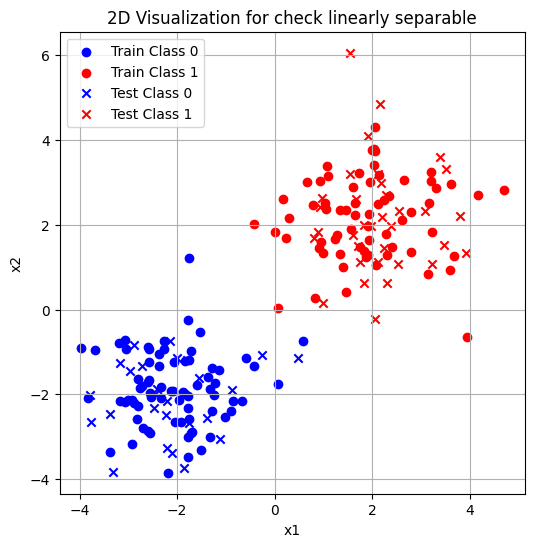

In [150]:
train_class0 = train[train[:, 2] == 0]
train_class1 = train[train[:, 2] == 1]

test_class0 = test[test[:, 2] == 0]
test_class1 = test[test[:, 2] == 1]

plt.figure(figsize=(6,6))
plt.scatter(train_class0[:, 0], train_class0[:, 1], color='blue', marker='o', label='Train Class 0')
plt.scatter(train_class1[:, 0], train_class1[:, 1], color='red', marker='o', label='Train Class 1')
plt.scatter(test_class0[:, 0], test_class0[:, 1], color='blue', marker='x', label='Test Class 0')
plt.scatter(test_class1[:, 0], test_class1[:, 1], color='red', marker='x', label='Test Class 1')

plt.title("2D Visualization for check linearly separable")
plt.xlabel("x1")
plt.ylabel("x2")
plt.legend()
plt.grid(True)
plt.show()

In [151]:
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")

X_train = torch.tensor(train[:, :2], dtype=torch.float32).to(device)
y_train = torch.tensor(train[:, 2], dtype=torch.long, device=device)
X_test  = torch.tensor(test[:, :2], dtype=torch.float32).to(device)
y_test = torch.tensor(test[:, 2], dtype=torch.long, device=device)

class Perceptron(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = torch.nn.Linear(2, 2)
    def forward(self, x):
        return self.linear(x)

model = Perceptron().to(device)

criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

epochs = 100
for epoch in range(epochs):
  model.train()
  optimizer.zero_grad()
  outputs = model(X_train)
  loss = criterion(outputs, y_train)
  loss.backward()
  optimizer.step()

  if (epoch+1) % 10 == 0:
        print(f"Epoch [{epoch+1}/{epochs}] Loss: {loss.item():.4f}")

model.eval()
with torch.no_grad():
  train_pred = torch.argmax(model(X_train), dim=1)
  test_pred  = torch.argmax(model(X_test),  dim=1)
  train_acc = (train_pred == y_train).float().mean().item()
  test_acc  = (test_pred  == y_test ).float().mean().item()

print(f"\nTrain Accuracy: {train_acc:.3f}")
print(f"Test Accuracy : {test_acc:.3f}")

Epoch [10/100] Loss: 0.9816
Epoch [20/100] Loss: 0.5937
Epoch [30/100] Loss: 0.4009
Epoch [40/100] Loss: 0.2983
Epoch [50/100] Loss: 0.2375
Epoch [60/100] Loss: 0.1981
Epoch [70/100] Loss: 0.1707
Epoch [80/100] Loss: 0.1505
Epoch [90/100] Loss: 0.1351
Epoch [100/100] Loss: 0.1229

Train Accuracy: 0.986
Test Accuracy : 0.983


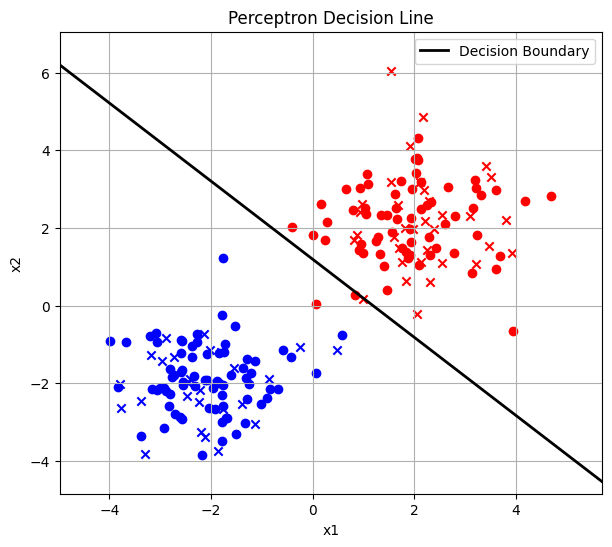

In [169]:
W = model.linear.weight.detach().cpu().numpy()
b = model.linear.bias.detach().cpu().numpy()
w0, w1 = W[0], W[1]
a, c = (w1 - w0)[0], (w1 - w0)[1]
d =  (b[1] - b[0])

all_xy = np.vstack([train[:, :2], test[:, :2]])
x_min, x_max = all_xy[:,0].min() - 1, all_xy[:,0].max() + 1
y_min, y_max = all_xy[:,1].min() - 1, all_xy[:,1].max() + 1

xs = np.array([x_min, x_max])
if abs(c) > 1e-12:
    ys = -(a*xs + d) / c
else:
    xs = np.array([-d/a, -d/a])
    ys = np.array([y_min, y_max])

plt.figure(figsize=(7,6))
plt.scatter(train[train[:,2]==0][:,0], train[train[:,2]==0][:,1], color='blue', marker='o')
plt.scatter(train[train[:,2]==1][:,0], train[train[:,2]==1][:,1], color='red',  marker='o')
plt.scatter(test[test[:,2]==0][:,0],  test[test[:,2]==0][:,1],  color='blue', marker='x')
plt.scatter(test[test[:,2]==1][:,0],  test[test[:,2]==1][:,1],  color='red',  marker='x')
plt.plot(xs, ys, 'k-', linewidth=2, label='Decision Boundary')

plt.xlim(x_min, x_max); plt.ylim(y_min, y_max)
plt.title('Perceptron Decision Line')
plt.xlabel('x1'); plt.ylabel('x2'); plt.legend(); plt.grid(True)
plt.show()

In [227]:
c00 = np.random.randn(50, 2) + np.array([-2, -2])
c01 = np.random.randn(50, 2) + np.array([ 2,  2])
y0  = np.zeros((100, 1))

c10 = np.random.randn(50, 2) + np.array([-2,  2])
c11 = np.random.randn(50, 2) + np.array([ 2, -2])
y1  = np.ones((100, 1))

class0 = np.vstack([c00, c01])
class1 = np.vstack([c10, c11])
data = np.vstack([
    np.hstack([class0, y0]),
    np.hstack([class1, y1])
])

np.random.shuffle(data)
n_train = int(len(data) * 0.7)
train = data[:n_train]
test  = data[n_train:]

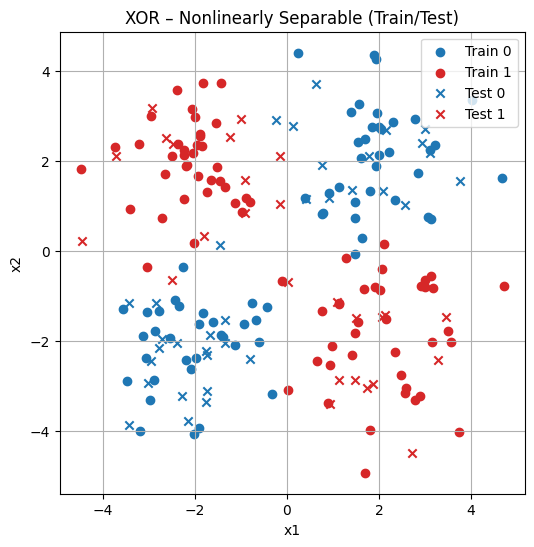

In [207]:
plt.figure(figsize=(6,6))
plt.scatter(train[train[:,2]==0][:,0], train[train[:,2]==0][:,1], c='tab:blue', marker='o', label='Train 0')
plt.scatter(train[train[:,2]==1][:,0], train[train[:,2]==1][:,1], c='tab:red',  marker='o', label='Train 1')
plt.scatter(test[test[:,2]==0][:,0],   test[test[:,2]==0][:,1],   c='tab:blue', marker='x', label='Test 0')
plt.scatter(test[test[:,2]==1][:,0],   test[test[:,2]==1][:,1],   c='tab:red',  marker='x', label='Test 1')
plt.legend(); plt.grid(True)
plt.title("XOR – Nonlinearly Separable (Train/Test)")
plt.xlabel("x1"); plt.ylabel("x2")
plt.show()

In [228]:
X_train = torch.tensor(train[:, :2], dtype=torch.float32).to(device)
y_train = torch.tensor(train[:, 2], dtype=torch.long, device=device)
X_test  = torch.tensor(test[:, :2], dtype=torch.float32).to(device)
y_test = torch.tensor(test[:, 2], dtype=torch.long, device=device)

In [229]:
class Perceptron(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = torch.nn.Linear(2, 2)
    def forward(self, x):
        return self.linear(x)

model = Perceptron().to(device)

criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

epochs = 1000
for epoch in range(epochs):
  model.train()
  optimizer.zero_grad()
  outputs = model(X_train)
  loss = criterion(outputs, y_train)
  loss.backward()
  optimizer.step()

  if (epoch+1) % 100 == 0:
        print(f"Epoch [{epoch+1}/{epochs}] Loss: {loss.item():.4f}")

model.eval()
with torch.no_grad():
  train_pred = torch.argmax(model(X_train), dim=1)
  test_pred  = torch.argmax(model(X_test),  dim=1)
  train_acc = (train_pred == y_train).float().mean().item()
  test_acc  = (test_pred  == y_test ).float().mean().item()

print(f"\nTrain Accuracy: {train_acc:.3f}")
print(f"Test Accuracy : {test_acc:.3f}")

Epoch [100/1000] Loss: 0.7095
Epoch [200/1000] Loss: 0.6933
Epoch [300/1000] Loss: 0.6925
Epoch [400/1000] Loss: 0.6923
Epoch [500/1000] Loss: 0.6922
Epoch [600/1000] Loss: 0.6922
Epoch [700/1000] Loss: 0.6922
Epoch [800/1000] Loss: 0.6922
Epoch [900/1000] Loss: 0.6922
Epoch [1000/1000] Loss: 0.6922

Train Accuracy: 0.493
Test Accuracy : 0.500


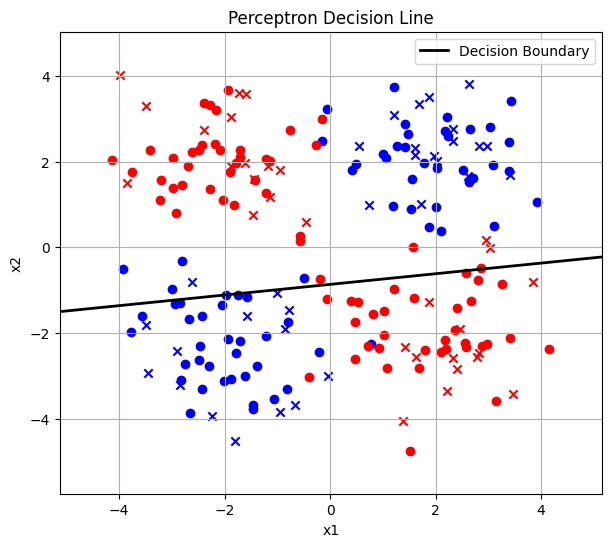

In [230]:
W = model.linear.weight.detach().cpu().numpy()
b = model.linear.bias.detach().cpu().numpy()
w0, w1 = W[0], W[1]
a, c = (w1 - w0)[0], (w1 - w0)[1]
d =  (b[1] - b[0])

all_xy = np.vstack([train[:, :2], test[:, :2]])
x_min, x_max = all_xy[:,0].min() - 1, all_xy[:,0].max() + 1
y_min, y_max = all_xy[:,1].min() - 1, all_xy[:,1].max() + 1

xs = np.array([x_min, x_max])
if abs(c) > 1e-12:
    ys = -(a*xs + d) / c
else:
    xs = np.array([-d/a, -d/a])
    ys = np.array([y_min, y_max])

plt.figure(figsize=(7,6))
plt.scatter(train[train[:,2]==0][:,0], train[train[:,2]==0][:,1], color='blue', marker='o')
plt.scatter(train[train[:,2]==1][:,0], train[train[:,2]==1][:,1], color='red',  marker='o')
plt.scatter(test[test[:,2]==0][:,0],  test[test[:,2]==0][:,1],  color='blue', marker='x')
plt.scatter(test[test[:,2]==1][:,0],  test[test[:,2]==1][:,1],  color='red',  marker='x')
plt.plot(xs, ys, 'k-', linewidth=2, label='Decision Boundary')

plt.xlim(x_min, x_max); plt.ylim(y_min, y_max)
plt.title('Perceptron Decision Line')
plt.xlabel('x1'); plt.ylabel('x2'); plt.legend(); plt.grid(True)
plt.show()

In [231]:
class LogisticRegression(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = torch.nn.Linear(2, 2)
    def forward(self, x):
        return self.linear(x)

model = LogisticRegression().to(device)
criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

epochs = 1000
for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()
    outputs = model(X_train)
    loss = criterion(outputs, y_train)
    loss.backward()
    optimizer.step()

    if (epoch + 1) % 100 == 0:
        print(f"Epoch [{epoch+1}/{epochs}] Loss: {loss.item():.4f}")

model.eval()
with torch.no_grad():
    train_pred = torch.argmax(model(X_train), dim=1)
    test_pred  = torch.argmax(model(X_test),  dim=1)
    train_acc = (train_pred == y_train).float().mean().item()
    test_acc  = (test_pred == y_test).float().mean().item()

print(f"\nLogistic Regression - Train Accuracy: {train_acc:.3f}")
print(f"Logistic Regression - Test Accuracy : {test_acc:.3f}")

Epoch [100/1000] Loss: 0.6922
Epoch [200/1000] Loss: 0.6922
Epoch [300/1000] Loss: 0.6922
Epoch [400/1000] Loss: 0.6922
Epoch [500/1000] Loss: 0.6922
Epoch [600/1000] Loss: 0.6922
Epoch [700/1000] Loss: 0.6922
Epoch [800/1000] Loss: 0.6922
Epoch [900/1000] Loss: 0.6922
Epoch [1000/1000] Loss: 0.6922

Logistic Regression - Train Accuracy: 0.493
Logistic Regression - Test Accuracy : 0.500


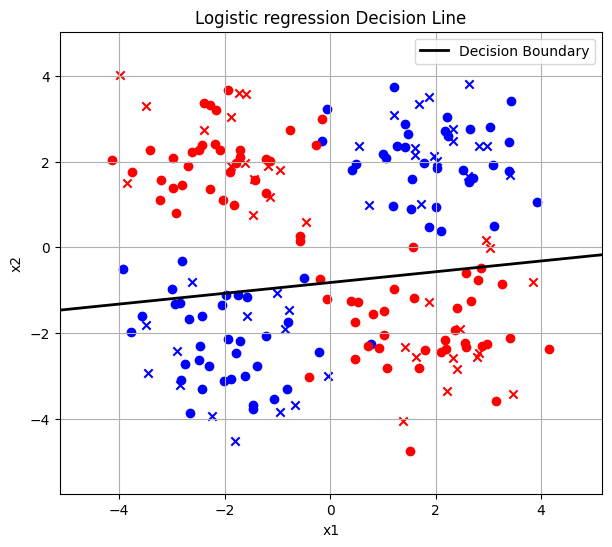

In [232]:
W = model.linear.weight.detach().cpu().numpy()
b = model.linear.bias.detach().cpu().numpy()
w0, w1 = W[0], W[1]
a, c = (w1 - w0)[0], (w1 - w0)[1]
d =  (b[1] - b[0])

all_xy = np.vstack([train[:, :2], test[:, :2]])
x_min, x_max = all_xy[:,0].min() - 1, all_xy[:,0].max() + 1
y_min, y_max = all_xy[:,1].min() - 1, all_xy[:,1].max() + 1

xs = np.array([x_min, x_max])
if abs(c) > 1e-12:
    ys = -(a*xs + d) / c
else:
    xs = np.array([-d/a, -d/a])
    ys = np.array([y_min, y_max])

plt.figure(figsize=(7,6))
plt.scatter(train[train[:,2]==0][:,0], train[train[:,2]==0][:,1], color='blue', marker='o')
plt.scatter(train[train[:,2]==1][:,0], train[train[:,2]==1][:,1], color='red',  marker='o')
plt.scatter(test[test[:,2]==0][:,0],  test[test[:,2]==0][:,1],  color='blue', marker='x')
plt.scatter(test[test[:,2]==1][:,0],  test[test[:,2]==1][:,1],  color='red',  marker='x')
plt.plot(xs, ys, 'k-', linewidth=2, label='Decision Boundary')

plt.xlim(x_min, x_max); plt.ylim(y_min, y_max)
plt.title('Logistic regression Decision Line')
plt.xlabel('x1'); plt.ylabel('x2'); plt.legend(); plt.grid(True)
plt.show()

In [217]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(2, 2)
        self.fc2 = nn.Linear(2, 2)
    def forward(self, x):
        h = torch.tanh(self.fc1(x))
        return self.fc2(h)

model = MLP().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)

epochs = 1000
for ep in range(epochs):
    model.train()
    optimizer.zero_grad()
    logits = model(X_train)
    loss = criterion(logits, y_train)
    loss.backward()
    optimizer.step()

    if (ep+1) % 100 == 0:
        with torch.no_grad():
            tr_acc = (torch.argmax(logits, 1) == y_train).float().mean().item()
        print(f"Epoch [{ep+1}/{epochs}]  loss={loss.item():.4f}  train_acc={tr_acc:.3f}")

model.eval()
with torch.no_grad():
    train_pred = torch.argmax(model(X_train), dim=1)
    test_pred  = torch.argmax(model(X_test),  dim=1)
    train_acc = (train_pred == y_train).float().mean().item()
    test_acc  = (test_pred  == y_test ).float().mean().item()

print(f"\nMLP - Train Accuracy: {train_acc:.3f}")
print(f"MLP - Test  Accuracy: {test_acc:.3f}")

Epoch [100/1000]  loss=0.5230  train_acc=0.593
Epoch [200/1000]  loss=0.4683  train_acc=0.679
Epoch [300/1000]  loss=0.4496  train_acc=0.700
Epoch [400/1000]  loss=0.4406  train_acc=0.700
Epoch [500/1000]  loss=0.4353  train_acc=0.714
Epoch [600/1000]  loss=0.4319  train_acc=0.714
Epoch [700/1000]  loss=0.4294  train_acc=0.721
Epoch [800/1000]  loss=0.4274  train_acc=0.729
Epoch [900/1000]  loss=0.4259  train_acc=0.721
Epoch [1000/1000]  loss=0.4245  train_acc=0.721

MLP - Train Accuracy: 0.721
MLP - Test  Accuracy: 0.700


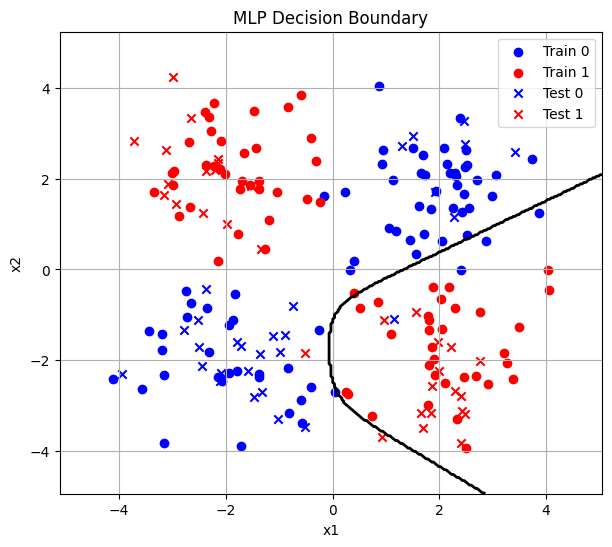

In [223]:
def plot_mlp_decision_line(model, train, test, X_train, X_test, title="MLP Decision Boundary"):
    model.eval()

    # 전체 데이터의 x, y 범위 계산
    all_xy = np.vstack([train[:, :2], test[:, :2]])
    x_min, x_max = all_xy[:,0].min() - 1, all_xy[:,0].max() + 1
    y_min, y_max = all_xy[:,1].min() - 1, all_xy[:,1].max() + 1

    # 격자(grid) 생성
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )
    grid = np.c_[xx.ravel(), yy.ravel()]
    grid_tensor = torch.tensor(grid, dtype=torch.float32).to(next(model.parameters()).device)

    # 모델 예측값 계산
    with torch.no_grad():
        pred = torch.argmax(model(grid_tensor), dim=1).cpu().numpy()
    Z = pred.reshape(xx.shape)

    # 시각화 (선만)
    plt.figure(figsize=(7,6))
    plt.contour(xx, yy, Z, levels=[0.5], colors='k', linewidths=2)  # 경계선만

    # 데이터 포인트
    plt.scatter(train[train[:,2]==0][:,0], train[train[:,2]==0][:,1], color='blue', marker='o', label='Train 0')
    plt.scatter(train[train[:,2]==1][:,0], train[train[:,2]==1][:,1], color='red',  marker='o', label='Train 1')
    plt.scatter(test[test[:,2]==0][:,0],  test[test[:,2]==0][:,1],  color='blue', marker='x', label='Test 0')
    plt.scatter(test[test[:,2]==1][:,0],  test[test[:,2]==1][:,1],  color='red',  marker='x', label='Test 1')

    plt.xlim(x_min, x_max)
    plt.ylim(y_min, y_max)
    plt.title(title)
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.legend()
    plt.grid(True)
    plt.show()
plot_mlp_decision_line(model, train, test, X_train, X_test, title="MLP Decision Boundary")